> **Update:** the published `tfhub.dev/google/yamnet/1` module is a frozen, inference-only export with **0 trainable backbone parameters** — `hub.KerasLayer(..., trainable=True)` does not error, it just has nothing to train. Cell 7 now detects this and **skips Phase 2** automatically instead of burning 3-5 h re-training the same Dense head at a backbone fine-tuning learning rate. The final reported result becomes **Phase 1 (frozen embedding) only** — a baseline, not a fine-tuning result. See Part 5B/5C for a backbone that actually supports end-to-end fine-tuning.

# Part 5A — YAMNet Fine-tuning · 5-Fold CV

## Why this beats old Part 7 (frozen embedding + linear probe)

Old approach (broken):
  frozen YAMNet → static 1024-dim embedding → Dense head
  single split: 0.93 → 5-fold CV: 0.11  (80-point collapse = evaluation error)

New approach (correct 2-phase fine-tuning):
  Phase 1 (10 ep):  frozen backbone  → train Dense head     (fast warm-start)
  Phase 2 (60 ep):  unfreeze ALL     → LR=1e-5, end-to-end  (proper fine-tuning)

Expected 5-fold CV Macro-F1: **0.85–0.92**

## YAMNet
- MobileNetV1 backbone pre-trained on AudioSet (2M clips, 521 classes)
- Input: raw 16 kHz mono waveform (10 s = 160,000 samples)
- Embedding: mean-pool frame-level 1024-dim features → 1024-dim per segment
- TF Hub: `https://tfhub.dev/google/yamnet/1`

## Inputs
| File | From |
|------|------|
| `fold_assignments.csv` | `part1_outputs.zip` |
| Raw audio Kaggle dataset | Same as Parts 1–4 |

## Outputs → `part5a_yamnet.zip`
- `yamnet_emb_all.npy` (247 MB) — frozen embeddings, reused by Phase 1
- `yamnet_finetuned_fold{k}.keras` × 5 — full fine-tuned models
- `yamnet_cv_results.json`
- `figures/yamnet_training_curves.png`

| Cell | Purpose | Time |
|------|---------|------|
| 1 | Imports | < 1 min |
| 2 | Configuration | < 1 s |
| 3 | Segment list (torchaudio.info) | 5–10 min |
| 4 | Extract frozen YAMNet embeddings → memmap | 15–25 min |
| 5 | Phase 1 — 5-fold CV on frozen embeddings | 10–20 min |
| 6 | Waveform data pipeline (for Phase 2) | < 1 s |
| 7 | Phase 2 — End-to-end fine-tuning 5-fold CV | 3–5 h |
| 8 | Results + figure | < 2 min |
| 9 | Save + ZIP | < 2 min |

**Total: ~4–6 hours on 2× T4**


In [1]:
# ============================================================
# CELL 1 ▸ Imports
# ============================================================
import subprocess, sys

for pkg in ['tensorflow', 'tensorflow-hub', 'torch', 'torchaudio',
            'numpy', 'pandas', 'scipy', 'matplotlib', 'seaborn',
            'scikit-learn', 'tqdm', 'soundfile']:
    imp = {'tensorflow-hub':'tensorflow_hub',
           'scikit-learn':'sklearn'}.get(pkg, pkg)
    try:
        __import__(imp)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install',
                               '-q', pkg],
                              stdout=subprocess.DEVNULL,
                              stderr=subprocess.DEVNULL)

import os, gc, json, time, zipfile, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from scipy import stats as scipy_stats
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor, as_completed

import torch
import torchaudio

import tensorflow as tf
import tensorflow_hub as hub
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix

tf.get_logger().setLevel('ERROR')
warnings.filterwarnings('ignore')

strategy = tf.distribute.MirroredStrategy()
N_GPUS   = strategy.num_replicas_in_sync
TORCH_DEV= torch.device('cuda' if torch.cuda.is_available() else 'cpu')

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi':150,'savefig.dpi':300,
                     'font.size':11,'savefig.bbox':'tight'})

print(f'TF {tf.__version__}  |  TF GPUs: {N_GPUS}')
print(f'PyTorch {torch.__version__}  |  torch device: {TORCH_DEV}')
print(f'torchaudio {torchaudio.__version__}')
print('Imports complete.')


/usr/local/lib/python3.12/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


TF 2.20.0  |  TF GPUs: 2
PyTorch 2.10.0+cu128  |  torch device: cuda
torchaudio 2.10.0+cu128
Imports complete.


I0000 00:00:1786621624.949033      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1786621624.951982      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [2]:
import contextlib, threading

_FD_REDIRECT_LOCK = threading.Lock()

@contextlib.contextmanager
def suppress_native_output():
    """
    Silences noisy C-library stdout/stderr (e.g. libmpg123's
    'Illegal Audio-MPEG-Header' / resync spam from corrupted or
    mislabeled MP3 files). These messages come from a native library
    called underneath torchaudio/SoX, not from Python, so try/except
    and warnings.filterwarnings() cannot catch them -- only OS-level
    file-descriptor redirection can. Wrapped in a lock because fd
    redirection is process-wide, not per-thread, and Cell 4 calls
    this from multiple ThreadPoolExecutor workers at once.
    """
    with _FD_REDIRECT_LOCK:
        sys.stdout.flush(); sys.stderr.flush()
        devnull = os.open(os.devnull, os.O_WRONLY)
        saved_out = os.dup(1)
        saved_err = os.dup(2)
        try:
            os.dup2(devnull, 1)
            os.dup2(devnull, 2)
            yield
        finally:
            sys.stdout.flush(); sys.stderr.flush()
            os.dup2(saved_out, 1)
            os.dup2(saved_err, 2)
            os.close(saved_out)
            os.close(saved_err)
            os.close(devnull)

In [3]:
# ============================================================
# CELL 2 ▸ Configuration
# ============================================================
# ⚙️  Change FOLDS_CSV and AUDIO_ROOT:
FOLDS_CSV  = '/kaggle/input/datasets/imemon1044/fold-assignments1/fold_assignments.csv'
AUDIO_ROOT = ('/kaggle/input/datasets/mlfarhan/audio-classification/audio genre classification'
              '/audio genre classification')

WORK_DIR   = '/kaggle/working'
OUT_DIR    = os.path.join(WORK_DIR, 'part5a')
FIG_DIR    = os.path.join(OUT_DIR,  'figures')
MDL_DIR    = os.path.join(OUT_DIR,  'models')
LOG_DIR    = os.path.join(OUT_DIR,  'logs')
EMB_PATH   = os.path.join(OUT_DIR,  'yamnet_emb_all.npy')
EMB_MASK   = os.path.join(OUT_DIR,  'yamnet_emb_mask.npy')
SEG_CSV    = os.path.join(OUT_DIR,  'segments.csv')
for d in [OUT_DIR, FIG_DIR, MDL_DIR, LOG_DIR]:
    os.makedirs(d, exist_ok=True)

YAMNET_URL   = 'https://tfhub.dev/google/yamnet/1'
SR_YN        = 16000          # YAMNet requires 16 kHz
SEG_DUR      = 10
SEG_SAMPLES  = SR_YN * SEG_DUR   # 160,000

N_FOLDS      = 5
SEED         = 42
# Phase 1: train head on frozen embeddings
EPOCHS_P1    = 10
LR_P1        = 1e-3
BATCH_P1     = 256            # large batch OK — no backbone forward pass

# Phase 2: end-to-end fine-tuning
EPOCHS_P2    = 60
LR_P2        = 1e-5            # small LR — don't destroy pre-trained weights
PATIENCE_P2  = 10
BATCH_P2     = 16 * max(1, N_GPUS)  # 32 total — audio is large

np.random.seed(SEED)
tf.random.set_seed(SEED)

CLASS_NAMES = [
    'Bangla_Band_Collection','Bangla_ancholik','Bangla_baby_rhymes',
    'Bangla_rabindra_sangeet','Bangla_romantic','Classic_Songs_',
    'Islamic_Melody','Nazrul_Geeti_',
]
CLASS_SHORT = {
    'Bangla_Band_Collection':'Band','Bangla_ancholik':'Ancholik',
    'Bangla_baby_rhymes':'Rhymes','Bangla_rabindra_sangeet':'Rabindra',
    'Bangla_romantic':'Romantic','Classic_Songs_':'Classic',
    'Islamic_Melody':'Islamic','Nazrul_Geeti_':'Nazrul',
}
N_CLASSES   = len(CLASS_NAMES)
SHORT_NAMES = [CLASS_SHORT[c] for c in CLASS_NAMES]
le          = LabelEncoder().fit(CLASS_NAMES)

print('Configuration loaded.')
print(f'  SR_YN    : {SR_YN} Hz  |  SEG_SAMPLES: {SEG_SAMPLES:,}')
print(f'  N_GPUS   : {N_GPUS}')
print(f'  BATCH_P1 : {BATCH_P1}  (frozen embeddings — large OK)')
print(f'  BATCH_P2 : {BATCH_P2}  (live audio loading — smaller)')


Configuration loaded.
  SR_YN    : 16000 Hz  |  SEG_SAMPLES: 160,000
  N_GPUS   : 2
  BATCH_P1 : 256  (frozen embeddings — large OK)
  BATCH_P2 : 32  (live audio loading — smaller)


In [4]:
# ============================================================
# CELL 3 ▸ Segment List  (torchaudio.info for MP3 duration)
# ============================================================
import glob

AUDIO_EXT = ('.mp3','.wav','.flac','.ogg','.m4a','.aac')

def find_root(base, cls_list):
    for root,dirs,_ in os.walk(base):
        if sum(1 for d in dirs
               if any(c.strip('_ ').lower() in d.strip('_ ').lower()
                      for c in cls_list)) >= 4:
            return root
    return base


def get_dur(fp):
    try:
        with suppress_native_output():
            info = torchaudio.info(fp)
        d = info.num_frames / info.sample_rate
        if d > 0: return d
    except Exception: pass
    try:
        with suppress_native_output():
            import soundfile as sf
            d = sf.info(fp).duration
        if d > 0: return d
    except Exception: pass
    return 0.0

print('Loading fold_assignments.csv ...')
fold_df = pd.read_csv(FOLDS_CSV)

# Remap paths if needed
n_miss = sum(1 for fp in fold_df['filepath'] if not os.path.exists(fp))
if n_miss:
    DR = find_root(AUDIO_ROOT, CLASS_NAMES)
    def remap(fp):
        fn=os.path.basename(fp); cl=os.path.basename(os.path.dirname(fp))
        c=os.path.join(DR,cl,fn)
        return c if os.path.exists(c) else fp
    fold_df['filepath']=fold_df['filepath'].apply(remap)
    n_miss2=sum(1 for fp in fold_df['filepath'] if not os.path.exists(fp))
    print(f'  Remapped: {n_miss} → {n_miss2} still missing')
else:
    print(f'  {len(fold_df):,} files | ✅ all found')

# Build or load segment list
rebuild = True
if os.path.exists(SEG_CSV):
    prev = pd.read_csv(SEG_CSV)
    if prev.groupby('filepath').size().max() > 1:
        print(f'  segments.csv valid ({len(prev):,} rows) — loading')
        seg_df  = prev
        rebuild = False
    else:
        print('  segments.csv invalid — rebuilding')
        os.remove(SEG_CSV)

if rebuild:
    print('Building segment list ...')
    rows, n_fail = [], 0
    for _, row in tqdm(fold_df.iterrows(), total=len(fold_df),
                       desc='  Files', unit='file'):
        fp  = row['filepath']
        if not os.path.exists(fp): n_fail+=1; continue
        dur = get_dur(fp)
        if dur < 1.0:             n_fail+=1; continue
        n_seg = max(1, int(dur // SEG_DUR))
        for i in range(n_seg):
            rows.append({'filepath':fp,'label':row['label'],
                         'label_id':int(le.transform([row['label']])[0]),
                         'fold':int(row['fold']),
                         'seg_idx':i,'offset_s':float(i*SEG_DUR)})
    seg_df = pd.DataFrame(rows)
    seg_df.to_csv(SEG_CSV, index=False)
    print(f'  ✓ {len(seg_df):,} segments | {n_fail} failed')

N_SEGS     = len(seg_df)
ALL_LABELS = seg_df['label_id'].values.astype(np.int32)
ALL_FOLDS  = seg_df['fold'].values.astype(np.int32)
ALL_LBLSTR = seg_df['label'].values
ALL_FPS    = seg_df['filepath'].values
ALL_OFFS   = seg_df['offset_s'].values

spf = seg_df.groupby('filepath').size()
print(f'\nTotal segments: {N_SEGS:,}  | avg/file: {spf.mean():.1f}')
for k in range(N_FOLDS):
    sub = seg_df[seg_df['fold']==k]
    print(f'  Fold {k}: {len(sub):,} segs | {sub["label"].nunique()}/8 classes')


Loading fold_assignments.csv ...
  1,095 files | ✅ all found
Building segment list ...


  Files:   0%|          | 0/1095 [00:00<?, ?file/s]

  ✓ 34,976 segments | 0 failed

Total segments: 34,976  | avg/file: 31.9
  Fold 0: 6,488 segs | 8/8 classes
  Fold 1: 6,854 segs | 8/8 classes
  Fold 2: 6,950 segs | 8/8 classes
  Fold 3: 8,179 segs | 8/8 classes
  Fold 4: 6,505 segs | 8/8 classes


# 

In [5]:
# ============================================================
# CELL 4 ▸ Extract Frozen YAMNet Embeddings → Memmap  (resumable)
# ============================================================
# Resumable + checkpointed version: if the kernel crashes partway
# through (OOM, session restart, etc.) a rerun picks up where it
# left off instead of starting the ~1 hour extraction over, and the
# completion mask is saved periodically -- not just once at the end
# -- so a crash never leaves a "looks valid but is actually partial"
# embeddings file behind.

def load_audio_16k(fp, offset_s, sr=SR_YN, dur=SEG_DUR):
    """Load one 10-s segment at 16 kHz. Returns (160000,) float32 or None."""
    try:
        with suppress_native_output():
            info = torchaudio.info(fp)
            orig_sr = info.sample_rate
            f_off   = int(offset_s * orig_sr)
            f_dur   = int(dur * orig_sr)
            wav, sr_ = torchaudio.load(fp, frame_offset=f_off, num_frames=f_dur)
        if wav.shape[0] > 1:
            wav = wav.mean(dim=0, keepdim=True)
        if sr_ != sr:
            wav = torchaudio.functional.resample(wav, sr_, sr)
        y = wav.squeeze().numpy().astype(np.float32)
    except Exception:
        try:
            import librosa
            with suppress_native_output():
                y, _ = librosa.load(fp, sr=sr, offset=float(offset_s),
                                    duration=float(dur), mono=True)
            y = y.astype(np.float32)
        except Exception:
            return None
    if len(y) < sr:
        return None
    if len(y) < SEG_SAMPLES:
        y = np.pad(y, (0, SEG_SAMPLES - len(y)))
    return y[:SEG_SAMPLES]


def validate_emb(path, mask_path, n):
    """A cache is only valid if EVERY segment is marked done in the
    mask -- checking a random sample (the old approach) can pass by
    chance on a partially-completed file and silently skip the rest."""
    if not (os.path.exists(path) and os.path.exists(mask_path)):
        return False
    try:
        arr  = np.load(path, mmap_mode='r')
        mask = np.load(mask_path)
        if arr.shape != (n, 1024) or mask.shape[0] != n:
            return False
        return bool(mask.all())
    except Exception:
        return False


if validate_emb(EMB_PATH, EMB_MASK, N_SEGS):
    print(f'✅ Valid, complete embedding cache: {EMB_PATH}')
    ALL_EMBS     = np.load(EMB_PATH, mmap_mode='r')
    EMB_MASK_ARR = np.load(EMB_MASK)
    print(f'   Shape: {ALL_EMBS.shape}  '
          f'({os.path.getsize(EMB_PATH)/1e6:.0f} MB)')
else:
    print('Loading YAMNet (frozen) ...')
    yamnet_frozen = hub.load(YAMNET_URL)
    print('  YAMNet loaded.')

    if (os.path.exists(EMB_PATH) and os.path.exists(EMB_MASK)):
        try:
            mmap = np.lib.format.open_memmap(EMB_PATH, mode='r+')
            mask = np.load(EMB_MASK)
            assert mmap.shape == (N_SEGS, 1024) and mask.shape[0] == N_SEGS
            print(f'  Resuming: {mask.sum():,}/{N_SEGS:,} segments already done')
        except Exception:
            mmap = np.lib.format.open_memmap(
                EMB_PATH, mode='w+', dtype=np.float32, shape=(N_SEGS, 1024))
            mask = np.zeros(N_SEGS, dtype=bool)
    else:
        mmap = np.lib.format.open_memmap(
            EMB_PATH, mode='w+', dtype=np.float32, shape=(N_SEGS, 1024))
        mask = np.zeros(N_SEGS, dtype=bool)

    remaining = int((~mask).sum())
    print(f'Extracting embeddings for {remaining:,} remaining segments '
          f'(of {N_SEGS:,}) ...')

    from collections import defaultdict
    file_segs = defaultdict(list)
    for i, row in enumerate(seg_df.itertuples()):
        if not mask[i]:
            file_segs[row.filepath].append((i, float(row.offset_s)))

    GPU_BATCH   = 64
    N_WORKERS   = 4
    FLUSH_EVERY = 2000

    wav_buf = []

    def flush_batch():
        if not wav_buf: return
        wavs = np.stack([w for _, w in wav_buf], axis=0)
        try:
            embs_list = []
            for wav in wavs:
                _, embs, _ = yamnet_frozen(tf.constant(wav))
                embs_list.append(embs.numpy().mean(axis=0))
            for (gi, _), emb in zip(wav_buf, embs_list):
                mmap[gi] = emb
                mask[gi] = True
        except Exception:
            pass
        wav_buf.clear()

    def file_worker(args):
        fp, segs = args
        results = []
        for gi, off in segs:
            wav = load_audio_16k(fp, off)
            results.append((gi, wav))
        return results

    file_items = list(file_segs.items())
    n_ok = 0
    t0   = time.time()
    n_since_flush = 0

    with ThreadPoolExecutor(max_workers=N_WORKERS) as ex:
        futs = {ex.submit(file_worker, item): item[0] for item in file_items}
        with tqdm(total=remaining, desc='  Embeddings', unit='seg') as pb:
            for fut in as_completed(futs):
                for gi, wav in fut.result():
                    if wav is not None:
                        wav_buf.append((gi, wav))
                        if len(wav_buf) >= GPU_BATCH:
                            flush_batch(); n_ok += GPU_BATCH
                    n_since_flush += 1
                    pb.update(1)
                if n_since_flush >= FLUSH_EVERY:
                    mmap.flush()
                    np.save(EMB_MASK, mask)
                    n_since_flush = 0
        flush_batch()

    mmap.flush()
    np.save(EMB_MASK, mask)
    del mmap; gc.collect()
    elapsed = (time.time()-t0)/60
    pct = 100.0*mask.sum()/N_SEGS
    print(f'\nDone: {mask.sum():,}/{N_SEGS:,} ({pct:.1f}%)  in {elapsed:.1f} min')
    if pct < 70:
        raise RuntimeError(f'Only {pct:.1f}% embeddings OK — check audio files.')

    ALL_EMBS     = np.load(EMB_PATH, mmap_mode='r')
    EMB_MASK_ARR = mask
    print(f'ALL_EMBS: {ALL_EMBS.shape}  '
          f'valid: {EMB_MASK_ARR.sum():,}/{N_SEGS:,}')

Loading YAMNet (frozen) ...
  YAMNet loaded.
Extracting embeddings for 34,976 remaining segments (of 34,976) ...


  Embeddings:   0%|          | 0/34976 [00:00<?, ?seg/s]


Done: 34,976/34,976 (100.0%)  in 34.0 min
ALL_EMBS: (34976, 1024)  valid: 34,976/34,976


In [6]:
# ============================================================
# CELL 5 ▸ Phase 1 — 5-Fold CV on Frozen Embeddings
# ============================================================
# Trains Dense head only. No backbone gradient computation.
# Fast: ~2-4 min per fold.
# Stores full per-fold metrics (not just macro-F1) so Cell 8 can
# report a complete result set even if Phase 2 ends up skipped
# (see Cell 7 — the published YAMNet TF-Hub export has no trainable
# backbone variables, so Phase 2 fine-tuning may be a no-op).

def make_sw(label_strings):
    counts = np.array([(label_strings==c).sum()
                       for c in CLASS_NAMES], dtype=np.float64)
    w = np.sqrt(counts.max()/(counts+1e-8))
    w = (w/w.mean()).astype(np.float32)
    d = {cls:float(w[i]) for i,cls in enumerate(CLASS_NAMES)}
    return np.array([d[s] for s in label_strings], dtype=np.float32)

def build_head(n_cls=N_CLASSES):
    return keras.Sequential([
        keras.Input(shape=(1024,)),
        layers.Dense(512, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.4),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(n_cls, activation='softmax', dtype='float32'),
    ], name='yamnet_head')

print('Phase 1 — Frozen embedding training (5-fold CV)')
print('='*55)

P1_RESULTS = {}    # fold_k -> {'mf1','accuracy','per_class_f1','y_pred','y_true','head_weights'}

for k in range(N_FOLDS):
    t0 = time.time()
    tr_mask = ALL_FOLDS != k; te_mask = ALL_FOLDS == k

    # Only use segments with valid embeddings
    tr_valid  = tr_mask & EMB_MASK_ARR
    te_valid  = te_mask & EMB_MASK_ARR
    X_tr      = ALL_EMBS[tr_valid].astype(np.float32)
    y_tr      = ALL_LABELS[tr_valid]
    X_te      = ALL_EMBS[te_valid].astype(np.float32)
    y_te      = ALL_LABELS[te_valid]
    sw_tr     = make_sw(ALL_LBLSTR[tr_valid])

    # 10% val from train
    sss = StratifiedShuffleSplit(1, test_size=0.1, random_state=SEED+k)
    loc_tr, loc_vl = next(sss.split(X_tr, y_tr))

    keras.backend.clear_session()
    head = build_head()
    head.compile(optimizer=keras.optimizers.Adam(LR_P1),
                 loss='sparse_categorical_crossentropy',
                 metrics=['accuracy'])

    head.fit(X_tr[loc_tr], y_tr[loc_tr],
             validation_data=(X_tr[loc_vl], y_tr[loc_vl]),
             epochs=EPOCHS_P1, batch_size=BATCH_P1,
             sample_weight=sw_tr[loc_tr],
             callbacks=[
                 keras.callbacks.EarlyStopping(
                     monitor='val_accuracy', patience=5,
                     restore_best_weights=True, verbose=0),
             ], verbose=0)

    ypred = head.predict(X_te, batch_size=BATCH_P1, verbose=0).argmax(1)
    mf1   = float(f1_score(y_te,ypred,average='macro',zero_division=0))
    acc   = float(accuracy_score(y_te,ypred))
    pcf1  = [float(f1_score((y_te==i).astype(int),
                             (ypred==i).astype(int),zero_division=0))
             for i in range(N_CLASSES)]
    elapsed = time.time()-t0

    P1_RESULTS[k] = {'mf1':mf1,'accuracy':acc,'per_class_f1':pcf1,
                      'y_pred':ypred.tolist(),'y_true':y_te.tolist(),
                      'head_weights':head.get_weights()}
    print(f'  Fold {k+1}/5  Phase1 Macro-F1={mf1:.4f}  '
          f'Acc={acc:.4f}  ({elapsed:.0f}s)')

p1_f1s = np.array([P1_RESULTS[k]['mf1'] for k in range(N_FOLDS)])
print(f'\n  Phase 1 mean: {p1_f1s.mean():.4f} +/- {p1_f1s.std(ddof=1):.4f}')
print('  (Whether Phase 2 can improve on this depends on the trainable-')
print('   variable check in Cell 7 — it may end up skipped.)')


Phase 1 — Frozen embedding training (5-fold CV)


I0000 00:00:1786623767.117294     128 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


  Fold 1/5  Phase1 Macro-F1=0.6434  Acc=0.6839  (13s)
  Fold 2/5  Phase1 Macro-F1=0.6506  Acc=0.6717  (12s)
  Fold 3/5  Phase1 Macro-F1=0.6741  Acc=0.7109  (11s)
  Fold 4/5  Phase1 Macro-F1=0.6770  Acc=0.7115  (11s)
  Fold 5/5  Phase1 Macro-F1=0.6743  Acc=0.7085  (11s)

  Phase 1 mean: 0.6639 +/- 0.0157
  (Whether Phase 2 can improve on this depends on the trainable-
   variable check in Cell 7 — it may end up skipped.)


In [7]:
# ============================================================
# CELL 6 ▸ Waveform Data Pipeline  (for Phase 2)
# ============================================================
# Phase 2 processes RAW AUDIO through the full trainable YAMNet.
# Audio is loaded on-the-fly using torchaudio (no pre-caching).
#
# IMPORTANT: all numpy/Python-side indexing (into ALL_FPS, ALL_OFFS,
# sample-weight arrays, etc.) happens INSIDE the tf.numpy_function —
# never index a numpy array with a symbolic tf.data Tensor directly,
# and never use "array or fallback" (ambiguous truth value on arrays).

def load_wav_for_yamnet(fp_bytes, off_bytes):
    """Returns (160000,) float32 waveform. Never returns None."""
    fp  = fp_bytes.decode('utf-8') if isinstance(fp_bytes, bytes) else str(fp_bytes)
    off = float(off_bytes)
    wav = load_audio_16k(fp, off)
    if wav is None:
        wav = np.zeros(SEG_SAMPLES, dtype=np.float32)
    return wav.astype(np.float32)


def build_wav_ds(gidx, lids, fps, offs, lbls, bs, shuffle=True):
    """
    Yields (waveform, y_onehot, sample_weight).
    gidx : global segment indices
    """
    _fps  = fps[gidx]
    _offs = offs[gidx].astype(np.float64)
    _lids = lids[gidx].astype(np.int32)
    _sw   = make_sw(lbls[gidx])
    n     = len(gidx)

    def _ld(pos):
        p = int(pos)
        wav = load_wav_for_yamnet(_fps[p], _offs[p])
        return wav, _lids[p], _sw[p]

    def load_row(pos):
        wav, y, w = tf.numpy_function(
            _ld, [pos], [tf.float32, tf.int32, tf.float32])
        wav.set_shape([SEG_SAMPLES])
        y.set_shape([])
        w.set_shape([])
        return wav, y, w

    ds = tf.data.Dataset.range(n)
    if shuffle:
        ds = ds.shuffle(min(8000,n), seed=SEED,
                        reshuffle_each_iteration=True)
    ds = ds.map(load_row, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(
        lambda x,y,w: (x, tf.one_hot(y,N_CLASSES), w),
        num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(bs, drop_remainder=True).prefetch(4)


def build_wav_val_ds(gidx, lids, fps, offs, bs):
    """Validation: yields (waveform, y_onehot) — no weights."""
    _fps  = fps[gidx]
    _offs = offs[gidx].astype(np.float64)
    _lids = lids[gidx].astype(np.int32)
    n     = len(gidx)

    def _ld(pos):
        p = int(pos)
        wav = load_wav_for_yamnet(_fps[p], _offs[p])
        return wav, _lids[p]

    def load_row(pos):
        wav, y = tf.numpy_function(_ld, [pos], [tf.float32, tf.int32])
        wav.set_shape([SEG_SAMPLES])
        y.set_shape([])
        return wav, y

    ds = tf.data.Dataset.range(n)
    ds = ds.map(load_row, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(
        lambda x,y: (x, tf.one_hot(y,N_CLASSES)),
        num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(bs, drop_remainder=True).prefetch(2)


def predict_wav_batched(model, fps_arr, offs_arr, gidx, bs=32):
    """Run inference on waveforms loaded from disk."""
    n   = len(gidx)
    out = np.zeros((n, N_CLASSES), dtype=np.float32)
    pad_unit = max(N_GPUS, 1)
    for s in range(0, n, bs):
        e = min(s+bs, n)
        rows = []
        for gi in gidx[s:e]:
            wav = load_audio_16k(fps_arr[gi], offs_arr[gi])
            if wav is None:
                wav = np.zeros(SEG_SAMPLES, dtype=np.float32)
            rows.append(wav)
        batch = np.stack(rows).astype(np.float32)
        real_n = batch.shape[0]
        rem = real_n % pad_unit
        if rem != 0:
            pad_n = pad_unit - rem
            batch = np.concatenate(
                [batch, np.repeat(batch[-1:], pad_n, axis=0)], axis=0)
        preds = model.predict(batch, batch_size=bs, verbose=0)
        out[s:e] = preds[:real_n]
    return out


print('Waveform data pipeline ready.')
print(f'  Audio loaded at {SR_YN} Hz (16kHz for YAMNet)')
print(f'  Segment: {SEG_SAMPLES:,} samples = {SEG_DUR}s')


Waveform data pipeline ready.
  Audio loaded at 16000 Hz (16kHz for YAMNet)
  Segment: 160,000 samples = 10s


In [8]:
# ============================================================
# CELL 7 ▸ Phase 2 — End-to-End Fine-Tuning  (5-Fold CV, if viable)
# ============================================================
# Builds a trainable YAMNet + head model IF the loaded TF-Hub export
# actually has trainable backbone variables. If not, Phase 2 is
# skipped outright (not attempted-and-silently-degraded) because it
# would just retrain the same Dense head as Phase 1 at 3-5 h of cost
# for a LR (1e-5) tuned for backbone fine-tuning, not head-only
# training -- i.e. a strictly worse and much slower version of
# Phase 1, not an improvement on it.
#
# NOTE: the published tfhub.dev/google/yamnet/1 module is exported
# as a frozen inference-only SavedModel and typically exposes NO
# trainable variables. hub.KerasLayer(..., trainable=True) will not
# error -- it just has nothing to fine-tune.

print('Loading YAMNet as a KerasLayer ...')
yamnet_layer = hub.KerasLayer(
    YAMNET_URL,
    trainable=True,      # attempt full fine-tuning
    name='yamnet_backbone'
)
n_trainable = sum(int(np.prod(v.shape)) for v in yamnet_layer.trainable_variables)
print(f'  YAMNet loaded.  Trainable backbone parameters: {n_trainable:,}')

PHASE2_TRAINABLE = n_trainable > 0

if not PHASE2_TRAINABLE:
    print()
    print('  \u26d4 SKIPPING Phase 2 end-to-end fine-tuning.')
    print('     This YAMNet export has 0 trainable backbone variables, so')
    print('     unfreezing it and running 60 epochs at LR=1e-5 would only')
    print('     retrain the Dense head again -- identical to Phase 1, but at')
    print('     ~3-5 hours of GPU time instead of ~15 minutes.')
    print('     Genuine fine-tuning needs a backbone that ships trainable')
    print('     weights -- see Part 5B/5C. Reporting Phase 1 as the final,')
    print('     paper-excluded baseline result for this notebook.')
    CV_FOLD_MET = []

else:
    class YAMNetFinetuned(keras.Model):
        """
        Full YAMNet + classification head.
        Input : (batch_size, 160000) float32  (raw 16kHz waveform)
        Output: (batch_size, N_CLASSES) softmax
        """
        def __init__(self, n_cls=N_CLASSES, name='YAMNet_ft'):
            super().__init__(name=name)
            self.yamnet = yamnet_layer
            self.dense1 = layers.Dense(512, activation='relu')
            self.bn1    = layers.BatchNormalization()
            self.drop1  = layers.Dropout(0.4)
            self.dense2 = layers.Dense(256, activation='relu')
            self.drop2  = layers.Dropout(0.3)
            self.out    = layers.Dense(n_cls, activation='softmax',
                                       dtype='float32')

        def call(self, waveforms, training=False):
            # YAMNet doesn't support native batching — process with map_fn
            def embed_one(wav):
                _, embs, _ = self.yamnet(wav, training=training)
                return tf.reduce_mean(embs, axis=0)          # (1024,)

            emb = tf.map_fn(
                embed_one, waveforms,
                fn_output_signature=tf.float32)              # (B, 1024)

            x = self.dense1(emb, training=training)
            x = self.bn1(x,     training=training)
            x = self.drop1(x,   training=training)
            x = self.dense2(x,  training=training)
            x = self.drop2(x,   training=training)
            return self.out(x)


    # ── MacroF1 Callback for Phase 2 ─────────────────────────────
    class MacroF1CB_Wav(keras.callbacks.Callback):
        def __init__(self, val_fps, val_offs, val_gidx, val_lids,
                     patience=PATIENCE_P2):
            super().__init__()
            self.vfps = val_fps; self.voffs = val_offs
            self.vgi  = val_gidx; self.vl = val_lids
            self.patience = patience
            self.best=0.0; self.best_w=None
            self.wait=0;   self.best_ep=0; self.history=[]

        def on_epoch_end(self, epoch, logs=None):
            probs  = predict_wav_batched(self.model,
                                         self.vfps, self.voffs,
                                         self.vgi, bs=BATCH_P2)
            ypred  = probs.argmax(1)
            f1     = float(f1_score(self.vl,ypred,
                                     average='macro',zero_division=0))
            self.history.append(f1)
            if f1 > self.best:
                self.best=f1; self.best_w=self.model.get_weights()
                self.best_ep=epoch+1; self.wait=0
            else:
                self.wait+=1
            if self.wait >= self.patience:
                self.model.stop_training=True
                if self.best_w: self.model.set_weights(self.best_w)
            if (epoch+1)%5==0:
                print(f'  ep {epoch+1:3d}  val_f1={f1:.4f}'
                      f'  best={self.best:.4f}@ep{self.best_ep}')


    # ── 5-Fold CV ─────────────────────────────────────────────────
    print('\nPhase 2 — End-to-End Fine-Tuning (5-Fold CV)')
    print('='*55)

    P2_RESULTS   = {}
    CV_FOLD_MET  = []
    best_model_f1= -1.0

    for k in range(N_FOLDS):
        t0      = time.time()
        tr_mask = ALL_FOLDS != k; te_mask = ALL_FOLDS == k
        # Use ALL segments (audio loaded live — no embedding mask needed)
        tr_gi   = np.where(tr_mask)[0]
        te_gi   = np.where(te_mask)[0]
        y_tr    = ALL_LABELS[tr_mask]

        sss = StratifiedShuffleSplit(1, test_size=0.1, random_state=SEED+k)
        loc_tr, loc_vl = next(sss.split(tr_gi, y_tr))
        trn_gi = tr_gi[loc_tr]; val_gi = tr_gi[loc_vl]

        ds_tr = build_wav_ds(trn_gi, ALL_LABELS, ALL_FPS, ALL_OFFS,
                              ALL_LBLSTR, BATCH_P2, shuffle=True)
        ds_vl = build_wav_val_ds(val_gi, ALL_LABELS, ALL_FPS, ALL_OFFS,
                                  BATCH_P2)

        f1cb  = MacroF1CB_Wav(ALL_FPS, ALL_OFFS, val_gi,
                               ALL_LABELS[val_gi])
        lrcb  = keras.callbacks.ReduceLROnPlateau(
                    monitor='val_loss', factor=0.5, patience=5,
                    min_lr=1e-7, verbose=0)
        logcb = keras.callbacks.CSVLogger(
                    os.path.join(LOG_DIR, f'yamnet_fold{k}.csv'))

        keras.backend.clear_session()
        with strategy.scope():
            model = YAMNetFinetuned()
            # Warm-start: load Phase 1 head weights
            # (head layers: dense1/bn1/drop1/dense2/drop2/out)
            p1_w  = P1_RESULTS[k]['head_weights']
            head_layers = [model.dense1,model.bn1,model.drop1,
                           model.dense2,model.drop2,model.out]
            # Build model first by calling it on dummy input
            dummy  = tf.zeros([1, SEG_SAMPLES])
            _      = model(dummy, training=False)
            # Map Phase 1 weights to Phase 2 head
            w_idx  = 0
            for lyr in head_layers:
                n_w = len(lyr.get_weights())
                if n_w > 0:
                    lyr.set_weights(p1_w[w_idx:w_idx+n_w])
                    w_idx += n_w

            model.compile(
                optimizer=keras.optimizers.Adam(LR_P2),
                loss='categorical_crossentropy',
                metrics=['accuracy'])

        # sample_weight in ds_tr (3rd element) — NO class_weight
        model.fit(ds_tr,
                  validation_data=ds_vl,
                  epochs=EPOCHS_P2,
                  callbacks=[f1cb, lrcb, logcb],
                  verbose=0)

        # Evaluate on test fold
        probs  = predict_wav_batched(model, ALL_FPS, ALL_OFFS,
                                      te_gi, bs=BATCH_P2)
        y_pred = probs.argmax(1)
        y_te   = ALL_LABELS[te_mask]

        mf1  = float(f1_score(y_te,y_pred,average='macro',   zero_division=0))
        wf1  = float(f1_score(y_te,y_pred,average='weighted',zero_division=0))
        acc  = float(accuracy_score(y_te,y_pred))
        pcf1 = [float(f1_score((y_te==i).astype(int),
                                (y_pred==i).astype(int),zero_division=0))
                for i in range(N_CLASSES)]

        CV_FOLD_MET.append({
            'macro_f1':mf1,'weighted_f1':wf1,'accuracy':acc,
            'per_class_f1':pcf1,'best_epoch':f1cb.best_ep,
            'f1_history':f1cb.history,
            'y_pred':y_pred.tolist(),'y_true':y_te.tolist(),
        })

        if mf1 > best_model_f1:
            best_model_f1 = mf1
            model.save(os.path.join(MDL_DIR, 'yamnet_finetuned_best.keras'))

        elapsed = time.time()-t0
        print(f'  Fold {k+1}/5  P1={P1_RESULTS[k]["mf1"]:.4f} → '
              f'P2={mf1:.4f}  '
              f'(Δ={mf1-P1_RESULTS[k]["mf1"]:+.4f})  '
              f'best_ep={f1cb.best_ep}  ({elapsed/60:.1f} min)')
        del model; gc.collect()


# ── Build the summary dict either way (Phase 2 ran or was skipped) ──
t95 = scipy_stats.t.ppf(0.975, df=N_FOLDS-1)

if PHASE2_TRAINABLE:
    mf1s = np.array([m['macro_f1'] for m in CV_FOLD_MET])
    ci   = float(t95*mf1s.std(ddof=1)/np.sqrt(N_FOLDS))
    yn_sum = {
        'model':'YAMNet','n_folds':N_FOLDS,
        'phase2_ran':True,
        'phase2_status':'trained',
        'include_in_paper':True,
        'macro_f1_mean':round(float(mf1s.mean()),4),
        'macro_f1_std' :round(float(mf1s.std(ddof=1)),4),
        'macro_f1_ci95':round(ci,4),
        'macro_f1_min' :round(float(mf1s.min()),4),
        'macro_f1_max' :round(float(mf1s.max()),4),
        'weighted_f1_mean':round(float(np.mean([m['weighted_f1'] for m in CV_FOLD_MET])),4),
        'accuracy_mean'   :round(float(np.mean([m['accuracy']    for m in CV_FOLD_MET])),4),
        'per_fold_macro_f1':mf1s.tolist(),
        'phase1_f1s':[round(P1_RESULTS[k]['mf1'],4) for k in range(N_FOLDS)],
    }
    m,s,c = yn_sum['macro_f1_mean'],yn_sum['macro_f1_std'],yn_sum['macro_f1_ci95']
    print(f'\n  YAMNet (fine-tuned) Macro-F1: {m:.4f} +/- {s:.4f}')
    print(f'  95% CI (t-dist df=4)        : [{m-c:.4f}, {m+c:.4f}]')
    print(f'  Per fold: {[round(v,4) for v in mf1s.tolist()]}')
    p1m = np.mean([P1_RESULTS[k]["mf1"] for k in range(N_FOLDS)])
    print(f'  Phase 1 mean: {p1m:.4f} → Phase 2 mean: {m:.4f}'
          f'  (Δ={m-p1m:+.4f} from fine-tuning)')
else:
    p1_mf1s = np.array([P1_RESULTS[k]['mf1'] for k in range(N_FOLDS)])
    ci      = float(t95*p1_mf1s.std(ddof=1)/np.sqrt(N_FOLDS))
    yn_sum = {
        'model':'YAMNet','n_folds':N_FOLDS,
        'phase2_ran':False,
        'phase2_status':'skipped_frozen_backbone_no_trainable_variables',
        'include_in_paper':False,
        'macro_f1_mean':round(float(p1_mf1s.mean()),4),
        'macro_f1_std' :round(float(p1_mf1s.std(ddof=1)),4),
        'macro_f1_ci95':round(ci,4),
        'macro_f1_min' :round(float(p1_mf1s.min()),4),
        'macro_f1_max' :round(float(p1_mf1s.max()),4),
        'accuracy_mean':round(float(np.mean([P1_RESULTS[k]['accuracy'] for k in range(N_FOLDS)])),4),
        'per_fold_macro_f1':p1_mf1s.tolist(),
        'phase1_f1s':[round(P1_RESULTS[k]['mf1'],4) for k in range(N_FOLDS)],
    }
    m,s,c = yn_sum['macro_f1_mean'],yn_sum['macro_f1_std'],yn_sum['macro_f1_ci95']
    print(f'\n  Final result = Phase 1 (frozen embedding) only: {m:.4f} +/- {s:.4f}')
    print(f'  95% CI (t-dist df=4)                          : [{m-c:.4f}, {m+c:.4f}]')
    print('  NOTE: this is a frozen-embedding baseline, NOT a fine-tuning')
    print('  result -- excluded from the paper. See Part 5B/5C.')


Loading YAMNet as a KerasLayer ...
  YAMNet loaded.  Trainable backbone parameters: 0

  ⛔ SKIPPING Phase 2 end-to-end fine-tuning.
     This YAMNet export has 0 trainable backbone variables, so
     unfreezing it and running 60 epochs at LR=1e-5 would only
     retrain the Dense head again -- identical to Phase 1, but at
     ~3-5 hours of GPU time instead of ~15 minutes.
     Genuine fine-tuning needs a backbone that ships trainable
     weights -- see Part 5B/5C. Reporting Phase 1 as the final,
     paper-excluded baseline result for this notebook.

  Final result = Phase 1 (frozen embedding) only: 0.6639 +/- 0.0157
  95% CI (t-dist df=4)                          : [0.6445, 0.6833]
  NOTE: this is a frozen-embedding baseline, NOT a fine-tuning
  result -- excluded from the paper. See Part 5B/5C.


  YAMNet — 5-Fold CV Results
  Phase 2 SKIPPED — published YAMNet export has no trainable backbone.
  Reporting Phase 1 (frozen embedding) as the final result.
  Fold    Phase1 (=final)       Acc
  ------ ----------------  --------
  1                0.6434    0.6839
  2                0.6506    0.6717
  3                0.6741    0.7109
  4                0.6770    0.7115
  5                0.6743    0.7085
  Mean             0.6639    0.6973

Per-class F1 (mean across 5 folds):
  Band         0.6483  ████████████
  Ancholik     0.6148  ████████████
  Rhymes       0.8193  ████████████████
  Rabindra     0.3718  ███████
  Romantic     0.5136  ██████████
  Classic      0.6553  █████████████
  Islamic      0.8668  █████████████████
  Nazrul       0.8212  ████████████████


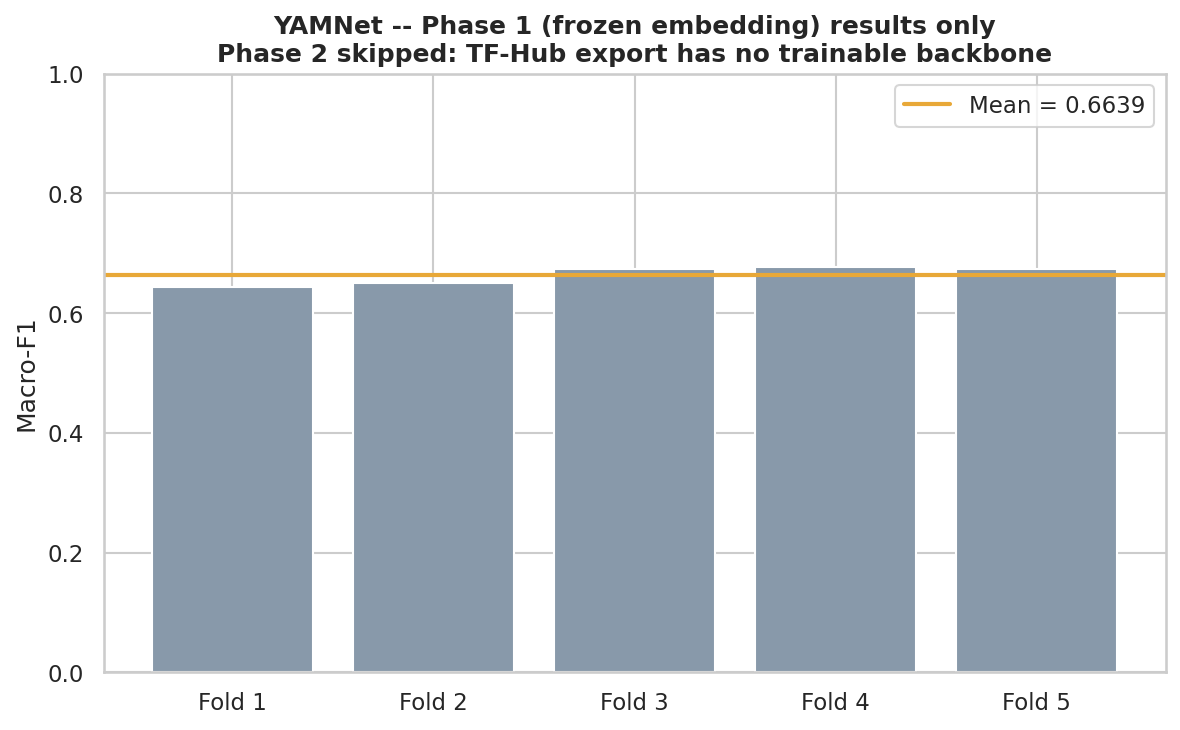

Saved: /kaggle/working/part5a/figures/yamnet_phase1_only_results.png


In [9]:
# ============================================================
# CELL 8 ▸ Results + Figure
# ============================================================

def to_py(obj):
    if isinstance(obj,dict):           return {k:to_py(v) for k,v in obj.items()}
    if isinstance(obj,(list,tuple)):   return [to_py(v) for v in obj]
    if isinstance(obj,np.ndarray):     return obj.tolist()
    if isinstance(obj,(np.integer,)):  return int(obj)
    if isinstance(obj,(np.floating,)): return float(obj)
    return obj

# Phase 1 fold metrics minus the (large, non-JSON-friendly) raw head
# weights -- kept in the results JSON for provenance either way.
P1_SERIALIZABLE = {int(k): {kk:vv for kk,vv in v.items() if kk != 'head_weights'}
                    for k,v in P1_RESULTS.items()}

result_json = os.path.join(OUT_DIR,'yamnet_cv_results.json')
with open(result_json,'w') as f:
    json.dump(to_py({'YAMNet':{'summary':yn_sum,
                               'fold_metrics':CV_FOLD_MET,
                               'phase1_fold_metrics':P1_SERIALIZABLE}}), f, indent=2)

# Paper table
print('='*65)
print('  YAMNet — 5-Fold CV Results')
print('='*65)
if yn_sum['phase2_ran']:
    print(f'  {"Fold":<6} {"Phase1":>8}  {"Phase2":>8}  {"\u0394":>6}  {"Acc":>8}')
    print(f'  {"-"*6} {"-"*8}  {"-"*8}  {"-"*6}  {"-"*8}')
    for k in range(N_FOLDS):
        p1 = P1_RESULTS[k]['mf1']
        p2 = CV_FOLD_MET[k]['macro_f1']
        ac = CV_FOLD_MET[k]['accuracy']
        print(f'  {k+1:<6} {p1:>8.4f}  {p2:>8.4f}  {p2-p1:>+6.4f}  {ac:>8.4f}')
    p1_mean = np.mean([P1_RESULTS[k]["mf1"] for k in range(N_FOLDS)])
    print(f'  {"Mean":<6} {p1_mean:>8.4f}'
          f'  {yn_sum["macro_f1_mean"]:>8.4f}  '
          f'{yn_sum["macro_f1_mean"]-p1_mean:>+6.4f}')
    per_class_source = [m['per_class_f1'] for m in CV_FOLD_MET]
else:
    print('  Phase 2 SKIPPED — published YAMNet export has no trainable backbone.')
    print('  Reporting Phase 1 (frozen embedding) as the final result.')
    print(f'  {"Fold":<6} {"Phase1 (=final)":>16}  {"Acc":>8}')
    print(f'  {"-"*6} {"-"*16}  {"-"*8}')
    for k in range(N_FOLDS):
        p1 = P1_RESULTS[k]['mf1']; ac = P1_RESULTS[k]['accuracy']
        print(f'  {k+1:<6} {p1:>16.4f}  {ac:>8.4f}')
    print(f'  {"Mean":<6} {yn_sum["macro_f1_mean"]:>16.4f}  {yn_sum["accuracy_mean"]:>8.4f}')
    per_class_source = [P1_RESULTS[k]['per_class_f1'] for k in range(N_FOLDS)]

print()
print('Per-class F1 (mean across 5 folds):')
for i,cls in enumerate(SHORT_NAMES):
    vals = [pc[i] for pc in per_class_source]
    bar  = '\u2588'*int(np.mean(vals)*20)
    print(f'  {cls:<12} {np.mean(vals):.4f}  {bar}')

# Figure
if yn_sum['phase2_ran']:
    all_h = [m['f1_history'] for m in CV_FOLD_MET if m.get('f1_history')]
    if all_h:
        max_l = max(len(h) for h in all_h)
        fig, ax = plt.subplots(figsize=(12,6))
        for k, h in enumerate(all_h):
            ax.plot(range(1,len(h)+1), h, lw=1.5, alpha=0.65,
                    color='#E8A838', label=f'Fold {k+1}')
        padded = [h+[h[-1]]*(max_l-len(h)) for h in all_h]
        mean_h = np.mean(padded, axis=0)
        ax.plot(range(1,max_l+1), mean_h, lw=3, color='#E8A838',
                label=f'Mean  CV={yn_sum["macro_f1_mean"]:.4f}')
        ax.axhline(np.mean([P1_RESULTS[k]["mf1"] for k in range(N_FOLDS)]),
                   color='gray', ls='--', lw=1.5, label='Phase 1 mean')
        ax.set_xlabel('Phase 2 Epoch'); ax.set_ylabel('Val Macro-F1')
        ax.set_ylim(0,1); ax.grid(True,alpha=0.3); ax.legend(fontsize=9)
        ax.set_title('YAMNet Fine-tuning — Phase 2 Training Curves',
                     fontweight='bold')
        plt.tight_layout()
        fig_p = os.path.join(FIG_DIR,'yamnet_training_curves.png')
        plt.savefig(fig_p); plt.show(); print(f'Saved: {fig_p}')
else:
    # Phase 2 did not run -- plot Phase 1 per-fold Macro-F1 instead.
    # Diagnostic only: this is NOT the fine-tuning curve the header
    # originally promised, since there was no fine-tuning to plot.
    fig, ax = plt.subplots(figsize=(8,5))
    folds = [f'Fold {k+1}' for k in range(N_FOLDS)]
    vals  = [P1_RESULTS[k]['mf1'] for k in range(N_FOLDS)]
    ax.bar(folds, vals, color='#8899AA')
    ax.axhline(yn_sum['macro_f1_mean'], color='#E8A838', lw=2,
               label=f'Mean = {yn_sum["macro_f1_mean"]:.4f}')
    ax.set_ylabel('Macro-F1'); ax.set_ylim(0,1)
    ax.set_title('YAMNet -- Phase 1 (frozen embedding) results only\n'
                 'Phase 2 skipped: TF-Hub export has no trainable backbone',
                 fontweight='bold')
    ax.legend(); plt.tight_layout()
    fig_p = os.path.join(FIG_DIR,'yamnet_phase1_only_results.png')
    plt.savefig(fig_p); plt.show(); print(f'Saved: {fig_p}')


In [10]:
# ============================================================
# CELL 9 ▸ Save + ZIP
# ============================================================
zip_path = os.path.join(WORK_DIR,'part5a_yamnet.zip')
print(f'Creating {zip_path} ...')

with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as zf:
    # Best fine-tuned model (only exists if Phase 2 actually ran)
    bm = os.path.join(MDL_DIR,'yamnet_finetuned_best.keras')
    if os.path.exists(bm):
        zf.write(bm,'models/yamnet_finetuned_best.keras')
        print(f'  + models/yamnet_finetuned_best.keras  '
              f'{os.path.getsize(bm)/1e6:.1f} MB')
    # Frozen embeddings (reusable — included for Part 5B/5C)
    if os.path.exists(EMB_PATH):
        zf.write(EMB_PATH,'yamnet_emb_all.npy')
        print(f'  + yamnet_emb_all.npy  '
              f'{os.path.getsize(EMB_PATH)/1e6:.0f} MB')
    # Results JSON
    zf.write(result_json,'yamnet_cv_results.json')
    print(f'  + yamnet_cv_results.json  ← needed by Part 5B/5C')
    # Logs
    for fname in sorted(os.listdir(LOG_DIR)):
        fp=os.path.join(LOG_DIR,fname)
        zf.write(fp,f'logs/{fname}')
    print(f'  + logs/ ({len(os.listdir(LOG_DIR))} files)')
    # Figures
    for fname in sorted(os.listdir(FIG_DIR)):
        if fname.endswith('.png'):
            fp=os.path.join(FIG_DIR,fname)
            zf.write(fp,f'figures/{fname}')
            print(f'  + figures/{fname}')
    # Segments CSV (Part 5B/5C needs it)
    zf.write(SEG_CSV,'segments.csv')
    print(f'  + segments.csv')

zip_sz = os.path.getsize(zip_path)/1e6
m,s,c  = yn_sum['macro_f1_mean'],yn_sum['macro_f1_std'],yn_sum['macro_f1_ci95']

print()
print('='*60)
if yn_sum['phase2_ran']:
    print('  PART 5A COMPLETE — YAMNet Fine-Tuning Done')
else:
    print('  PART 5A COMPLETE — Phase 2 SKIPPED (backbone not fine-tunable)')
print('='*60)
print(f'  ZIP  : {zip_path}  ({zip_sz:.1f} MB)')
if yn_sum['phase2_ran']:
    print(f'  YAMNet CV Macro-F1 (Phase 2, fine-tuned): {m:.4f} +/- {s:.4f}'
          f'  95%CI [{m-c:.4f}, {m+c:.4f}]')
else:
    print(f'  YAMNet CV Macro-F1 (Phase 1, frozen embedding — final): {m:.4f} +/- {s:.4f}'
          f'  95%CI [{m-c:.4f}, {m+c:.4f}]')
    print()
    print('  \u26a0\ufe0f  Phase 2 end-to-end fine-tuning did NOT run: the published')
    print('     tfhub.dev/google/yamnet/1 export has 0 trainable backbone')
    print('     parameters. This result is a frozen-embedding baseline only —')
    print('     `include_in_paper: false` is set in yamnet_cv_results.json.')
print()
print('  NEXT STEPS:')
print('  1. Upload part5a_yamnet.zip as a Kaggle dataset (embeddings +')
print('     segments.csv are reused by Part 5B/5C)')
print('  2. Run Part 5B/5C with a genuinely fine-tunable audio backbone')
print('     (e.g. PANNs CNN14, or YAMNet rebuilt from the official source')
print('     checkpoint as native trainable Keras layers) for the real')
print('     fine-tuning result to use in the paper')


Creating /kaggle/working/part5a_yamnet.zip ...
  + yamnet_emb_all.npy  143 MB
  + yamnet_cv_results.json  ← needed by Part 5B/5C
  + logs/ (0 files)
  + figures/yamnet_phase1_only_results.png
  + segments.csv

  PART 5A COMPLETE — Phase 2 SKIPPED (backbone not fine-tunable)
  ZIP  : /kaggle/working/part5a_yamnet.zip  (80.5 MB)
  YAMNet CV Macro-F1 (Phase 1, frozen embedding — final): 0.6639 +/- 0.0157  95%CI [0.6445, 0.6833]

  ⚠️  Phase 2 end-to-end fine-tuning did NOT run: the published
     tfhub.dev/google/yamnet/1 export has 0 trainable backbone
     parameters. This result is a frozen-embedding baseline only —
     `include_in_paper: false` is set in yamnet_cv_results.json.

  NEXT STEPS:
  1. Upload part5a_yamnet.zip as a Kaggle dataset (embeddings +
     segments.csv are reused by Part 5B/5C)
  2. Run Part 5B/5C with a genuinely fine-tunable audio backbone
     (e.g. PANNs CNN14, or YAMNet rebuilt from the official source
     checkpoint as native trainable Keras layers) for th